<a href="https://colab.research.google.com/github/Kevin1077/Bank-project/blob/Dataset-Loading%2C-EDA/Dataset_Loading%2C_EDA_%26_Data_Cleaning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

DATASET LOADING , EDA & DATA CLEANING DATASET LOADING


Import Libraries


In [74]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer

Dataset Loading

In [75]:
df_bank= pd.read_csv("/content/drive/MyDrive/Colab Notebooks/dataset/bank dataset .csv", sep=";", na_values=["unknown","Unknown","UNKOWN"])

In [76]:
print("Dataset loaded successfully!")

Dataset loaded successfully!


 Initial Data Inspection

In [77]:
print("First 5 rows:")
df_bank.head()


First 5 rows:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,NaN,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,NaN,3,jun,199,4,-1,0,NaN,no
4,59,blue-collar,married,secondary,no,0,yes,no,NaN,5,may,226,1,-1,0,NaN,no


In [78]:
print("Last 5 rows:")
df_bank.tail()


Last 5 rows:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
4516,33,services,married,secondary,no,-333,yes,no,cellular,30,jul,329,5,-1,0,NaN,no
4517,57,self-employed,married,tertiary,yes,-3313,yes,yes,NaN,9,may,153,1,-1,0,NaN,no
4518,57,technician,married,secondary,no,295,no,no,cellular,19,aug,151,11,-1,0,NaN,no
4519,28,blue-collar,married,secondary,no,1137,no,no,cellular,6,feb,129,4,211,3,other,no
4520,44,entrepreneur,single,tertiary,no,1136,yes,yes,cellular,3,apr,345,2,249,7,other,no


In [79]:
print("Dataset Shape:")
df_bank.shape

Dataset Shape:


(4521, 17)

In [80]:
print("Dataset Information:")
df_bank.info()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        4521 non-null   int64 
 1   job        4483 non-null   object
 2   marital    4521 non-null   object
 3   education  4334 non-null   object
 4   default    4521 non-null   object
 5   balance    4521 non-null   int64 
 6   housing    4521 non-null   object
 7   loan       4521 non-null   object
 8   contact    3197 non-null   object
 9   day        4521 non-null   int64 
 10  month      4521 non-null   object
 11  duration   4521 non-null   int64 
 12  campaign   4521 non-null   int64 
 13  pdays      4521 non-null   int64 
 14  previous   4521 non-null   int64 
 15  poutcome   816 non-null    object
 16  y          4521 non-null   object
dtypes: int64(7), object(10)
memory usage: 600.6+ KB


In [81]:
print("Statistical Summary:")
df_bank.describe()

Statistical Summary:


,age,balance,day,duration,campaign,pdays,previous
count,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000
mean,41.170095,1422.657819,15.915284,263.961292,2.793630,39.766645,0.542579
std,10.576211,3009.638142,8.247667,259.856633,3.109807,100.121124,1.693562
min,19.000000,-3313.000000,1.000000,4.000000,1.000000,-1.000000,0.000000
25%,33.000000,69.000000,9.000000,104.000000,1.000000,-1.000000,0.000000
50%,39.000000,444.000000,16.000000,185.000000,2.000000,-1.000000,0.000000
75%,49.000000,1480.000000,21.000000,329.000000,3.000000,-1.000000,0.000000
max,87.000000,71188.000000,31.000000,3025.000000,50.000000,871.000000,25.000000


In [82]:
print("Missing Values:")
df_bank.isnull().sum()

Missing Values:


,0
age,0
job,38
marital,0
education,187
default,0
balance,0
housing,0
loan,0
contact,1324
day,0


In [83]:
print("missing values in %")
df_bank.isna().sum()/len(df_bank)*100

missing values in %


,0
age,0.000000
job,0.840522
marital,0.000000
education,4.136253
default,0.000000
balance,0.000000
housing,0.000000
loan,0.000000
contact,29.285556
day,0.000000


In [84]:
print("Duplicate Rows:")
df_bank.duplicated().sum()

Duplicate Rows:


np.int64(0)

 Exploratory Data Analysis (EDA)


In [85]:
print("Age Statistics:")
df_bank["age"].describe()

Age Statistics:


,age
count,4521.000000
mean,41.170095
std,10.576211
min,19.000000
25%,33.000000
50%,39.000000
75%,49.000000
max,87.000000


In [86]:
print("Balance Statistics:")
df_bank["balance"].describe()

Balance Statistics:


,balance
count,4521.000000
mean,1422.657819
std,3009.638142
min,-3313.000000
25%,69.000000
50%,444.000000
75%,1480.000000
max,71188.000000


In [87]:
print("Customers by Job:")
df_bank["job"].value_counts()

Customers by Job:


,count
job,
management,969
blue-collar,946
technician,768
admin.,478
services,417
retired,230
self-employed,183
entrepreneur,168
unemployed,128


In [88]:
print("Customers by Marital Status:")
df_bank["marital"].value_counts()

Customers by Marital Status:


,count
marital,
married,2797
single,1196
divorced,528


In [89]:
print("Term Deposit Subscription:")
df_bank["y"].value_counts()

Term Deposit Subscription:


,count
y,
no,4000
yes,521


In [90]:
print("Subscription Percentage:")
df_bank["y"].value_counts(normalize=True) * 100

Subscription Percentage:


,proportion
y,
no,88.476001
yes,11.523999


Data Visualization

In [91]:
sns.set_theme(style="whitegrid")

Visualization 1: Age Distribution

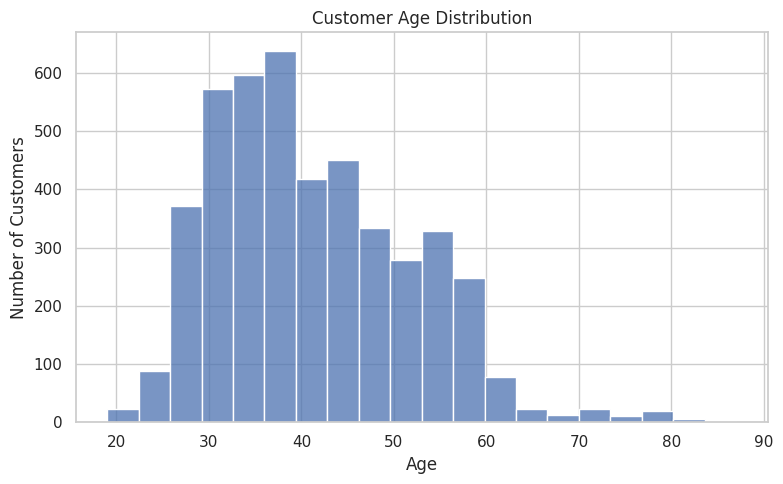

In [92]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df_bank, x="age", bins=20)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()


Visualization 2: Subscription Status

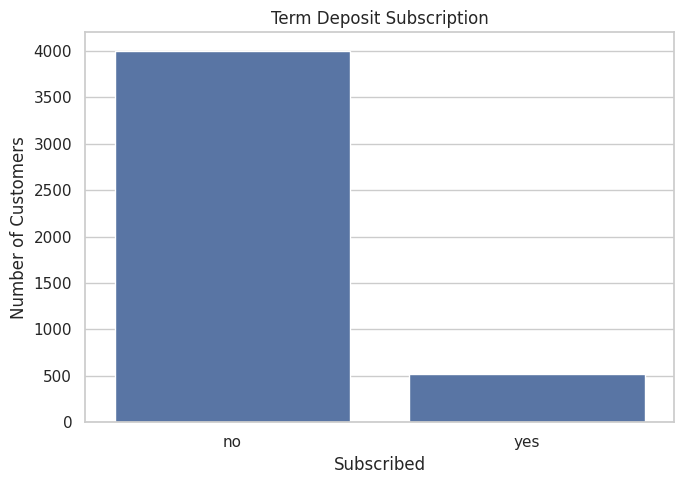

In [93]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df_bank, x="y")

plt.title("Term Deposit Subscription")
plt.xlabel("Subscribed")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

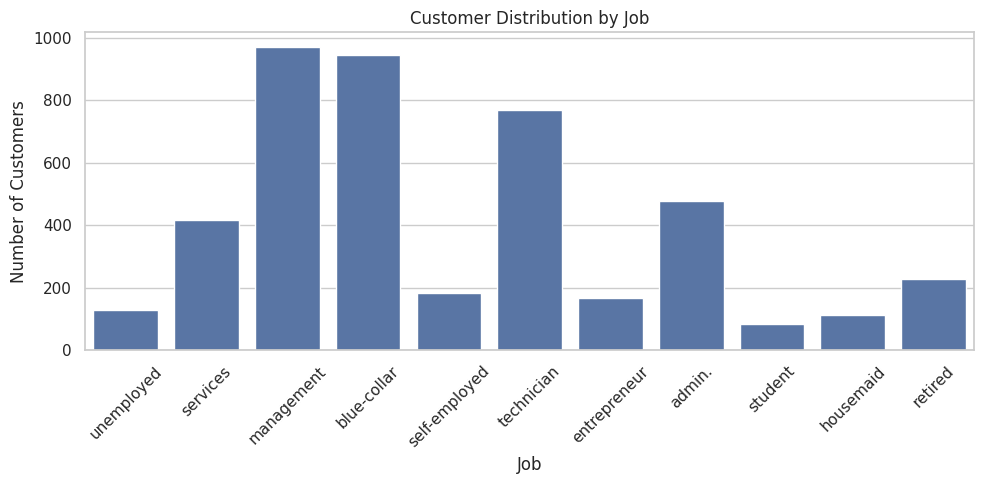

In [94]:
plt.figure(figsize=(10, 5))

sns.countplot(data=df_bank, x="job")

plt.title("Customer Distribution by Job")
plt.xlabel("Job")
plt.ylabel("Number of Customers")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

 Data Cleaning

1.Missing Value Identification


In [95]:
df_bank.isna().sum()/len(df_bank)*100


,0
age,0.000000
job,0.840522
marital,0.000000
education,4.136253
default,0.000000
balance,0.000000
housing,0.000000
loan,0.000000
contact,29.285556
day,0.000000


In [96]:
df_bank.drop(columns=['poutcome'],inplace=True)

In [97]:
columns_to_clean = ['job']

for col in columns_to_clean:
    df_bank.dropna(subset=[col], inplace=True)